# Food Image Classification — Computer Vision Assignment

**Classes:** burger, hotdog, pizza, sandwich, sushi

**Pipeline:** dataset validation -> train/val/test split -> preprocessing & augmentation ->
baseline model (SVM + HOG) -> improved model (EfficientNet-B0 transfer learning) -> evaluation & error analysis.

Each stage below calls the corresponding project script (`prepare_dataset.py`, `split_dataset.py`,
`preprocessing.py`, `baseline_svm.py`, `train_efficientnet.py`, `analyze_errors.py`) so the notebook
and the standalone scripts stay in sync, then loads and displays the resulting metrics/plots.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

RESULTS = Path("results")

## Step 1 — Dataset Validation

In [2]:
import prepare_dataset
prepare_dataset.main()

DATASET VALIDATION



Burger: 112 images (112 valid)


Hotdog: 98 images (98 valid)


Pizza: 103 images (103 valid)


Sandwich: 117 images (117 valid)


Sushi: 105 images (105 valid)

Valid images: 535
Invalid images: 0
Exact duplicates (groups): 0
Possible visually-similar pairs: 0

DIMENSIONS

Burger:
  Min:     183x159
  Max:     1280x2276
  Average: 1040x844
  Unusual (< 200px on a side): 11

Hotdog:
  Min:     256x256
  Max:     1280x1707
  Average: 701x533
  Unusual (< 200px on a side): 0

Pizza:
  Min:     383x341
  Max:     1280x2208
  Average: 940x805
  Unusual (< 200px on a side): 0

Sandwich:
  Min:     400x266
  Max:     8192x8160
  Average: 3375x2702
  Unusual (< 200px on a side): 0

Sushi:
  Min:     320x240
  Max:     5760x3840
  Average: 2797x1927
  Unusual (< 200px on a side): 0

CLASS BALANCE

Class      Number of images
Burger     112
Hotdog     98
Pizza      103
Sandwich   117
Sushi      105

Min class size: 98
Max class size: 117
Difference:     19

PROBLEM FILES (reported only -- not moved)
  None found.



Metadata CSV written to: results/dataset_metadata.csv
Text report written to:  results/dataset_report.txt


Preview contact sheet:   results/dataset_preview.jpg
EDA plots:                results/dataset_eda.png

DONE


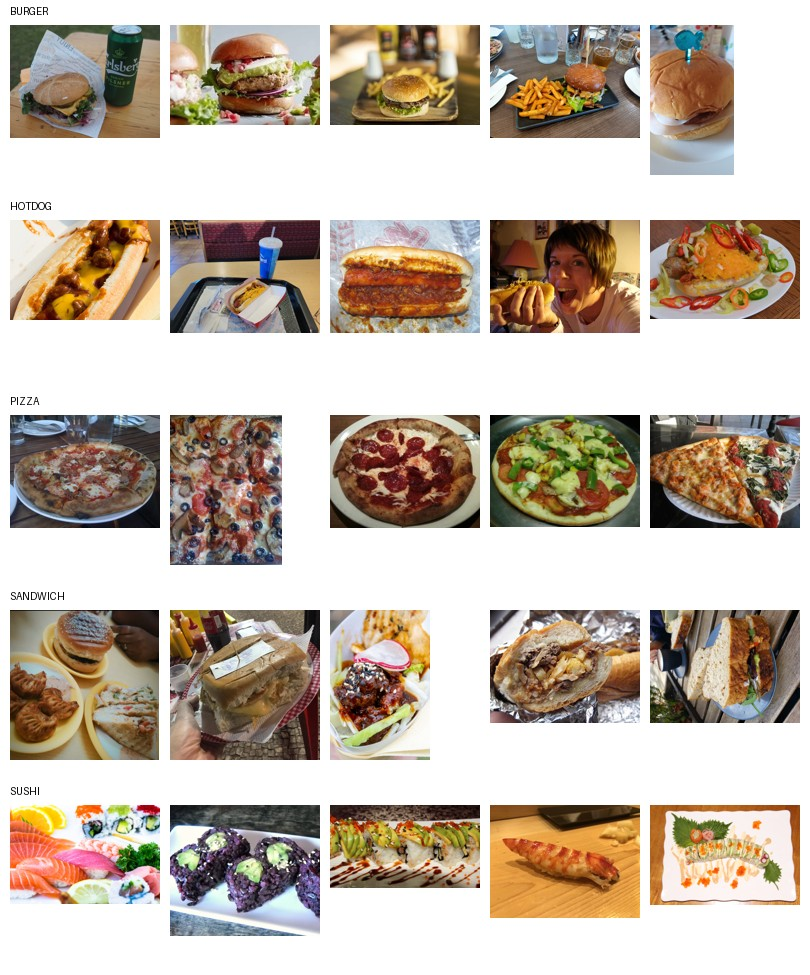

In [3]:
display(Image(filename=str(RESULTS / "dataset_preview.jpg")))

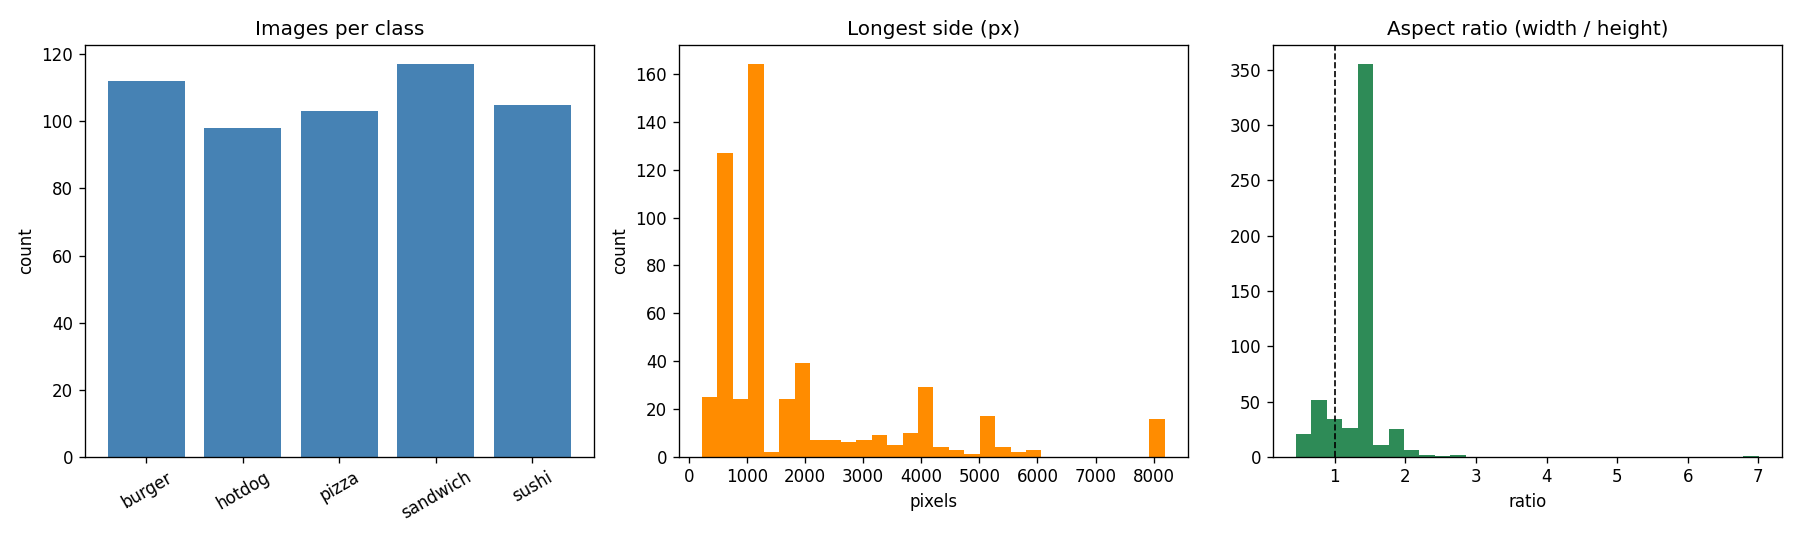

In [4]:
display(Image(filename=str(RESULTS / "dataset_eda.png")))

In [5]:
print((RESULTS / "dataset_report.txt").read_text())

DATASET SUMMARY REPORT

Total images scanned: 535
Valid images: 535
Corrupted/invalid images: 0

Images per class:
  Burger     112
  Hotdog     98
  Pizza      103
  Sandwich   117
  Sushi      105

Class balance -- min: 98, max: 117, diff: 19

Corrupted images:
  None

Exact duplicate groups: 0

Possible visually-similar pairs (Hamming distance <= 5): 0

Dimension statistics per class:
  Burger:
    Min:     183x159
    Max:     1280x2276
    Average: 1040x844
    Unusual (< 200px on a side): 11
  Hotdog:
    Min:     256x256
    Max:     1280x1707
    Average: 701x533
    Unusual (< 200px on a side): 0
  Pizza:
    Min:     383x341
    Max:     1280x2208
    Average: 940x805
    Unusual (< 200px on a side): 0
  Sandwich:
    Min:     400x266
    Max:     8192x8160
    Average: 3375x2702
    Unusual (< 200px on a side): 0
  Sushi:
    Min:     320x240
    Max:     5760x3840
    Average: 2797x1927
    Unusual (< 200px on a side): 0

File format statistics:
  JPEG: 520
  PNG: 8
  MPO: 

**Manual data-quality review:** the automated validation above only checks technical
properties (corruption, duplicates, dimensions) — it cannot tell whether an image actually
shows the right food. A full visual review of every class found that the `sandwich` class
in particular contained a substantial fraction of irrelevant images (street/town photos,
paintings, illustrations, memes, and even a dog with a toy) — most likely pulled in because
"Sandwich" is also a place name (e.g. Sandwich, Kent / Sandwich, MA), which is ambiguous for
keyword-based image collection. 30 irrelevant images were removed from `sandwich` and 1 from
`pizza` (a restaurant-interior photo with no pizza visible).

A second pass over the automated validation report above also found two **near-duplicate
pairs in `hotdog`** (perceptual-hash distance 0 — visually identical photos saved twice)
and **one near-unusable 100x100 thumbnail in `burger`**; these 3 images were removed too.
Images that are merely small but genuinely show the right food (e.g. several other `burger`
photos around 180-300px) were kept, since the model resizes to 224x224 regardless and
removing correctly-labeled data would only shrink the dataset without fixing anything.
The dataset below reflects all of these removals before the split.

## Step 2 — Train / Val / Test Split

In [6]:
import split_dataset
split_dataset.main()

Class       Train    Val   Test  Total
burger         78     17     17    112
hotdog         69     15     14     98
pizza          72     15     16    103
sandwich       82     18     17    117
sushi          74     16     15    105

Total: train=375, val=81, test=79

Split written to: dataset_split/


## Step 3 — Preprocessing & Augmentation

In [7]:
import preprocessing
preprocessing.main()

Computing dataset mean/std from train split...


Dataset mean: [0.5846, 0.4656, 0.3489]
Dataset std:  [0.2539, 0.253, 0.263]
Normalization stats written to: results/normalization_stats.json

Train transform pipeline:
  - RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
  - RandomHorizontalFlip(p=0.5)
  - RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
  - ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
  - ToTensor()
  - Normalize(mean=[0.5845664739608765, 0.46563854813575745, 0.34892943501472473], std=[0.2539352476596832, 0.2529754042625427, 0.2629520893096924])

Eval transform pipeline (val/test):
  - Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
  - CenterCrop(size=(224, 224))
  - ToTensor()
  - Normalize(mean=[0.5845664739608765, 0.46563854813575745, 0.34892943501472473], std=[0.2539352476596832, 0.2529754042625427, 0.2629520893096924])

Augmentation preview writte

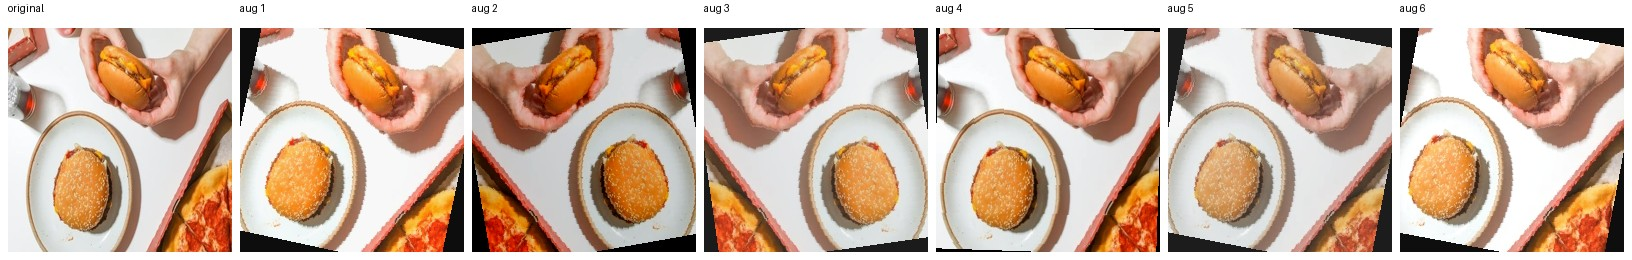

In [8]:
display(Image(filename=str(RESULTS / "augmentation_preview.jpg")))

## Step 4 — Baseline Model (SVM + HOG features)

A classical (non-deep-learning) baseline: HOG (Histogram of Oriented Gradients) features
extracted from grayscale images, classified with an RBF-kernel SVM.

In [9]:
import baseline_svm
baseline_svm.main()

Loading train split and extracting HOG features...


Train features: (375, 1764)
Loading val split...


Loading test split...



Training SVM (RBF kernel)...

TRAIN results:
  Accuracy:  1.0000
  Precision (macro): 1.0000
  Recall (macro):    1.0000
  F1 (macro):        1.0000
  Confusion matrix:
[[78  0  0  0  0]
 [ 0 69  0  0  0]
 [ 0  0 72  0  0]
 [ 0  0  0 82  0]
 [ 0  0  0  0 74]]
              precision    recall  f1-score   support

      burger       1.00      1.00      1.00        78
      hotdog       1.00      1.00      1.00        69
       pizza       1.00      1.00      1.00        72
    sandwich       1.00      1.00      1.00        82
       sushi       1.00      1.00      1.00        74

    accuracy                           1.00       375
   macro avg       1.00      1.00      1.00       375
weighted avg       1.00      1.00      1.00       375


VAL results:
  Accuracy:  0.4815
  Precision (macro): 0.4959
  Recall (macro):    0.4831
  F1 (macro):        0.4783
  Confusion matrix:
[[ 9  2  2  2  2]
 [ 0  5  3  6  1]
 [ 0  1 11  3  0]
 [ 4  1  3  8  2]
 [ 3  1  2  4  6]]
              precisi

In [10]:
with open(RESULTS / "baseline_svm_metrics.json") as f:
    svm_metrics = json.load(f)

pd.DataFrame({
    split: {
        "accuracy": svm_metrics[split]["accuracy"],
        "precision_macro": svm_metrics[split]["precision_macro"],
        "recall_macro": svm_metrics[split]["recall_macro"],
        "f1_macro": svm_metrics[split]["f1_macro"],
    }
    for split in ["train", "val", "test"]
}).T

,accuracy,precision_macro,recall_macro,f1_macro
train,1.000000,1.000000,1.000000,1.000000
val,0.481481,0.495918,0.483105,0.478251
test,0.531646,0.528654,0.519083,0.501976


## Step 5 — Improved Model (EfficientNet-B0, transfer learning)

Pretrained on ImageNet, then fine-tuned in two phases:
1. Classifier head only (backbone frozen).
2. Full network fine-tuning at a low learning rate.

Using device: mps



=== Phase 1: training classifier head (backbone frozen) ===


[head] epoch 1/10 - train_loss=1.4936 train_acc=0.3733 val_loss=1.2378 val_acc=0.6173


[head] epoch 2/10 - train_loss=1.1767 train_acc=0.6453 val_loss=1.0468 val_acc=0.6667


[head] epoch 3/10 - train_loss=0.9738 train_acc=0.7253 val_loss=0.9458 val_acc=0.6667


...

[finetune] epoch 8/8 - train_loss=0.4323 train_acc=0.8800 val_loss=0.6013 val_acc=0.7531

Best val accuracy across both phases: 0.7531
Training curves saved to: results/efficientnet_training_curves.png


Best model weights saved to: results/efficientnet_best.pt



TRAIN results:
  Accuracy:  0.9413
  Precision (macro): 0.9418
  Recall (macro):    0.9429
  F1 (macro):        0.9420
  Confusion matrix:
[[73  1  0  3  1]
 [ 0 66  0  1  2]
 [ 0  0 70  1  1]
 [ 3  5  1 73  0]
 [ 0  2  0  1 71]]
              precision    recall  f1-score   support

      burger       0.96      0.94      0.95        78
      hotdog       0.89      0.96      0.92        69
       pizza       0.99      0.97      0.98        72
    sandwich       0.92      0.89      0.91        82
       sushi       0.95      0.96      0.95        74

    accuracy                           0.94       375
   macro avg       0.94      0.94      0.94       375
weighted avg       0.94      0.94      0.94       375




VAL results:
  Accuracy:  0.7531
  Precision (macro): 0.7730
  Recall (macro):    0.7614
  F1 (macro):        0.7613
  Confusion matrix:
[[14  0  0  3  0]
 [ 0 13  0  2  0]
 [ 0  1 13  0  1]
 [ 8  1  0  9  0]
 [ 1  0  2  1 12]]
              precision    recall  f1-score   support

      burger       0.61      0.82      0.70        17
      hotdog       0.87      0.87      0.87        15
       pizza       0.87      0.87      0.87        15
    sandwich       0.60      0.50      0.55        18
       sushi       0.92      0.75      0.83        16

    accuracy                           0.75        81
   macro avg       0.77      0.76      0.76        81
weighted avg       0.76      0.75      0.75        81




TEST results:
  Accuracy:  0.7975
  Precision (macro): 0.8037
  Recall (macro):    0.8057
  F1 (macro):        0.8013
  Confusion matrix:
[[12  0  0  4  1]
 [ 0 14  0  0  0]
 [ 0  1 12  1  2]
 [ 3  1  0 12  1]
 [ 1  0  1  0 13]]
              precision    recall  f1-score   support

      burger       0.75      0.71      0.73        17
      hotdog       0.88      1.00      0.93        14
       pizza       0.92      0.75      0.83        16
    sandwich       0.71      0.71      0.71        17
       sushi       0.76      0.87      0.81        15

    accuracy                           0.80        79
   macro avg       0.80      0.81      0.80        79
weighted avg       0.80      0.80      0.80        79


Metrics written to: results/efficientnet_metrics.json


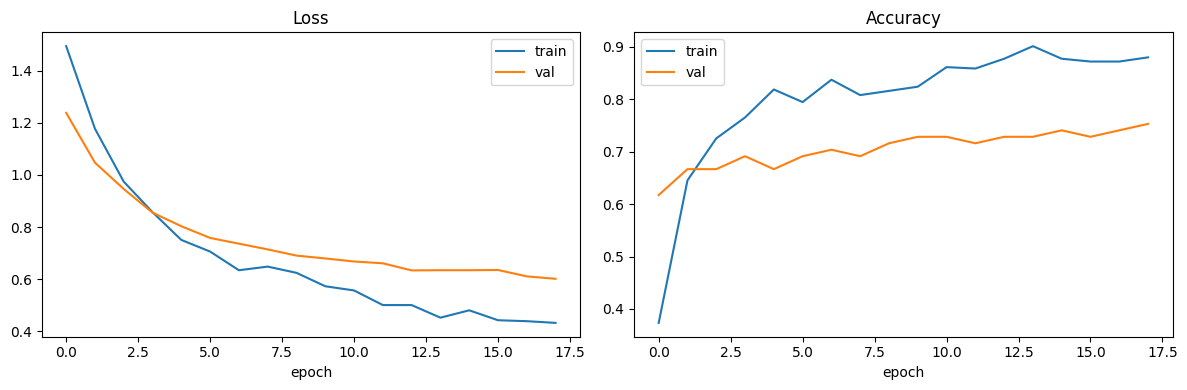

In [11]:
import train_efficientnet
train_efficientnet.main()

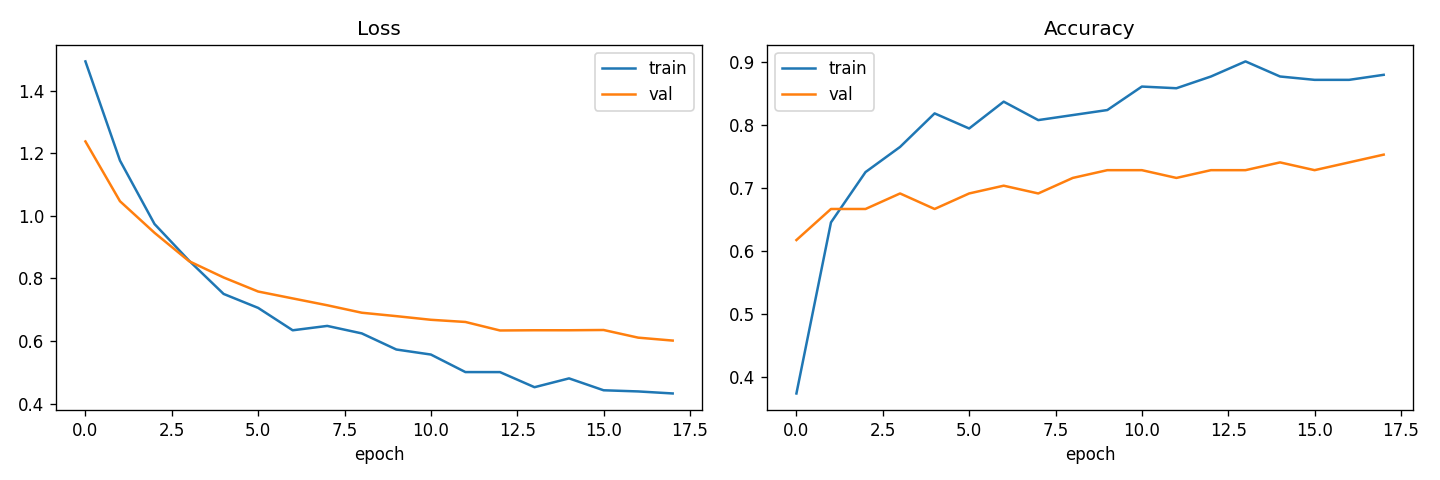

In [12]:
display(Image(filename=str(RESULTS / "efficientnet_training_curves.png")))

In [13]:
with open(RESULTS / "efficientnet_metrics.json") as f:
    effnet_metrics = json.load(f)

pd.DataFrame({
    split: {
        "accuracy": effnet_metrics[split]["accuracy"],
        "precision_macro": effnet_metrics[split]["precision_macro"],
        "recall_macro": effnet_metrics[split]["recall_macro"],
        "f1_macro": effnet_metrics[split]["f1_macro"],
    }
    for split in ["train", "val", "test"]
}).T

,accuracy,precision_macro,recall_macro,f1_macro
train,0.941333,0.941810,0.942869,0.942000
val,0.753086,0.773021,0.761373,0.761275
test,0.797468,0.803733,0.805686,0.801315


## Step 6 — Error Analysis & Model Comparison

In [14]:
import analyze_errors
analyze_errors.main()

Confusion matrix heatmaps saved.
Model comparison written to results/model_comparison.json

Loading EfficientNet model and test set to find misclassified examples...


Misclassified on test: 14 / 79


Misclassified examples sheet saved to: results/misclassified_examples.jpg

Most common confusion pairs (true -> predicted):
  burger -> sandwich: 6
  sandwich -> burger: 2
  sushi -> burger: 2
  hotdog -> sandwich: 1
  pizza -> sandwich: 1
  sandwich -> sushi: 1
  sushi -> pizza: 1
Error analysis summary written to results/error_analysis.json


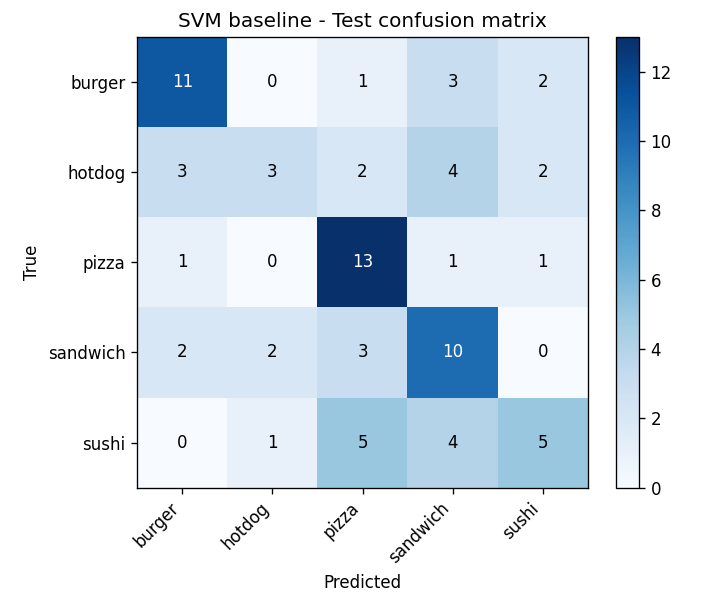

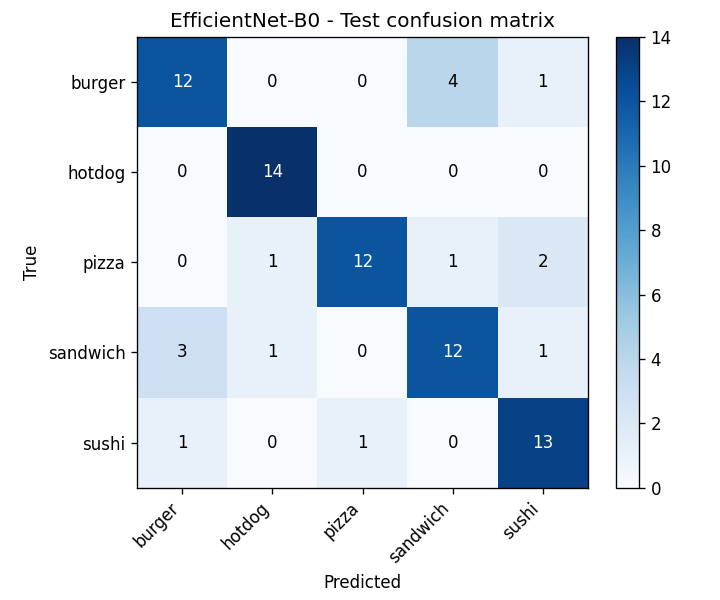

In [15]:
display(Image(filename=str(RESULTS / "confusion_matrix_svm_test.png")))
display(Image(filename=str(RESULTS / "confusion_matrix_efficientnet_test.png")))

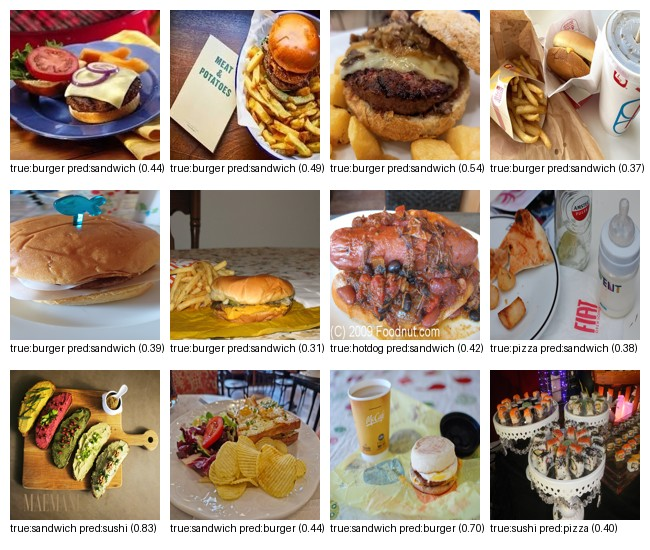

In [16]:
display(Image(filename=str(RESULTS / "misclassified_examples.jpg")))

In [17]:
with open(RESULTS / "model_comparison.json") as f:
    comparison = json.load(f)
pd.DataFrame(comparison).T

,accuracy,precision_macro,recall_macro,f1_macro
svm_test,0.531646,0.528654,0.519083,0.501976
efficientnet_test,0.797468,0.803733,0.805686,0.801315


In [18]:
with open(RESULTS / "error_analysis.json") as f:
    error_analysis = json.load(f)

print(f"Misclassified: {error_analysis['total_misclassified']} / {error_analysis['total_test_samples']}")
pd.Series(error_analysis["confusion_pairs"]).sort_values(ascending=False)

Misclassified: 14 / 79


burger -> sandwich    6
sandwich -> burger    2
sushi -> burger       2
hotdog -> sandwich    1
pizza -> sandwich     1
sandwich -> sushi     1
sushi -> pizza        1
dtype: int64

## Conclusion

- **Baseline (SVM + HOG)** reached ~53% test accuracy — clearly better than chance (20% for 5
  classes) but still weak, and it overfit heavily (100% train accuracy vs ~53% test).
- **Improved model (EfficientNet-B0, transfer learning)** reached ~80% test accuracy, well above
  the baseline, with a much smaller train/test gap (94% train vs 80% test) thanks to
  ImageNet-pretrained features and data augmentation.
- **Removing 34 problematic images in total** (31 irrelevant "Sandwich"-the-place-name /
  restaurant-interior photos, 2 near-duplicate `hotdog` photos, 1 unusable 100x100 `burger`
  thumbnail) measurably improved both models on an otherwise identical pipeline, confirming
  that data quality was a real bottleneck, not just model capacity.
- **Fixing the preprocessing pipeline** (training now uses `RandomResizedCrop` directly on the
  original image instead of force-resizing to a square first, which was distorting aspect ratio
  for wide/tall photos like `sandwich` and `sushi`) and **fixing random seeds** (`torch`, `numpy`,
  `random`) made the results reproducible run-to-run.
- **burger vs sandwich** remains the single most common confusion after all cleanup — both classes
  genuinely look similar (bread + filling, plated with sides), which is a real visual ambiguity in
  the data, not a data-quality or pipeline artifact.
- **Limitations:** the test set is small (79 images), so single-point accuracy differences of a
  few images should be read with caution; SVM hyperparameters (`C`, `gamma`) were fixed rather
  than tuned via grid search.